# ERA5-pretrained and from-scratch runs vs. LAM (06 km) conventional obs

Companion to `plot_metrics_vs_global_obs.ipynb`, for the high-resolution nest. Same three
training chains under

`/pscratch/sd/b/bhuang95/nested-eagle/0.25deg-06km/production/era5-gfs-hrrr/stage2c/diagnostics/`

**Only the nested-cutout runs can appear in a true LAM comparison.** The
`*.convobs.nested-lam.nc` files exist for `era5-gfs-hrrr` stage2a/2b/2c and for
`gfs-hrrr` stage1a/1b/1c. `era5-gfs-hrrr` stage1a/1b and all three `gfs-only` runs are
global-grid models with no LAM nest, so their obs-metrics ran `model_type: global` and wrote
no `nested-lam` output. There is nothing to fix there; the file simply cannot exist.

So this notebook has two sections:

1. **LAM verification** (`convobs.nested-lam`) — the six nested runs, verified on the 06 km
   nest. This is the real high-resolution comparison.
2. **CONUS verification** (`convobs.{global,nested-global}.conus`) — all eleven runs. This
   is the *coarse* verification restricted to the CONUS box, which is the only way the
   global-grid runs can be put on the same axes as the nested ones over the nest region.
   Read it as "how does the global model do over CONUS", **not** as a 06 km LAM score.

Color encodes the stage and linestyle the run (era5-gfs-hrrr solid, gfs-hrrr dashed,
gfs-only dash-dot), the same as in the global-obs notebook, so a given series is the same
everywhere. Curves are drawn without the bootstrap confidence band.


In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
import xarray as xr

# niceplots.py lives in the shared baselines directory, not next to this notebook
NICEPLOTS_DIR = os.path.abspath("../../../../../baselines")
if NICEPLOTS_DIR not in sys.path:
    sys.path.insert(0, NICEPLOTS_DIR)

import niceplots
from niceplots import plot_surface_vars, plot_level_vars, nice_names, get_units

# ~/nice.mplstyle is not present on Perlmutter; fall back rather than raising
try:
    plt.style.use("~/nice.mplstyle")
except OSError:
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "#e6e5e1",   # recessive grid
        "grid.linewidth": 0.8,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "lines.linewidth": 2.0,
        "font.size": 12,
    })

In [2]:
DIAGDIR = "/pscratch/sd/b/bhuang95/nested-eagle/0.25deg-06km/production/era5-gfs-hrrr/stage2c/diagnostics"
FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)

# The LAM nest exists only for the nested-cutout runs: the ERA5 stage2 chain and the
# from-scratch gfs-hrrr chain. gfs-only is a global model and wrote no nested-lam file.
LAM_EXPERIMENTS = {
    "era5-gfs-hrrr 2a": "inference-era5-gfs-hrrr-stage2a",
    "era5-gfs-hrrr 2b": "inference-era5-gfs-hrrr-stage2b",
    "era5-gfs-hrrr 2c": "inference-era5-gfs-hrrr-stage2c",
    "gfs-hrrr 1a": "inference-gfs-hrrr-stage1a",
    "gfs-hrrr 1b": "inference-gfs-hrrr-stage1b",
    "gfs-hrrr 1c": "inference-gfs-hrrr-stage1c",
}

# For the CONUS-subregion section: label -> (experiment directory, file tag).
# Plain global grids wrote `global`, nested cutout grids wrote `nested-global`.
CONUS_EXPERIMENTS = {
    "era5-gfs-hrrr 1a": ("inference-era5-gfs-hrrr-stage1a", "global"),
    "era5-gfs-hrrr 1b": ("inference-era5-gfs-hrrr-stage1b", "global"),
    "era5-gfs-hrrr 2a": ("inference-era5-gfs-hrrr-stage2a", "nested-global"),
    "era5-gfs-hrrr 2b": ("inference-era5-gfs-hrrr-stage2b", "nested-global"),
    "era5-gfs-hrrr 2c": ("inference-era5-gfs-hrrr-stage2c", "nested-global"),

    "gfs-hrrr 1a": ("inference-gfs-hrrr-stage1a", "nested-global"),
    "gfs-hrrr 1b": ("inference-gfs-hrrr-stage1b", "nested-global"),
    "gfs-hrrr 1c": ("inference-gfs-hrrr-stage1c", "nested-global"),

    "gfs-only 1a": ("inference-gfs-only-stage1a", "global"),
    "gfs-only 1b": ("inference-gfs-only-stage1b", "global"),
    "gfs-only 1c": ("inference-gfs-only-stage1c", "global"),
}

SHORT_LEAD = {"fhr": slice(49)}   # the 0-48 h zoom this notebook has always carried


In [3]:
# Color encodes the *stage*, linestyle encodes the *run*.
# Keep in sync with plot_metrics_vs_global_obs.ipynb — a series must look the same in both.
# Dropping the global-grid runs for the LAM section does not repaint the rest.
#
#   stage a -> light green, stage b -> blue, stage c -> black
#   era5-gfs-hrrr -> solid, gfs-hrrr -> dashed, gfs-only -> dash-dot
#
# Caveat carried over from the earlier version: the weight of light green (1.42:1 against
# white) and orange (1.97:1) makes those lines read faint where curves overlap. The table
# view at the end gives the numbers when the curves are too close to separate by eye.
STYLE = {
    "era5-gfs-hrrr 1a": ("orange",     "-"),
    "era5-gfs-hrrr 1b": ("red",        "-"),
    "era5-gfs-hrrr 2a": ("lightgreen", "-"),
    "era5-gfs-hrrr 2b": ("blue",       "-"),
    "era5-gfs-hrrr 2c": ("black",      "-"),

    "gfs-hrrr 1a":      ("lightgreen", "--"),
    "gfs-hrrr 1b":      ("blue",       "--"),
    "gfs-hrrr 1c":      ("black",      "--"),

    "gfs-only 1a":      ("lightgreen", "-."),
    "gfs-only 1b":      ("blue",       "-."),
    "gfs-only 1c":      ("black",      "-."),
}


In [4]:
def single_plot(ax, dsdict, metric_name, varname, sel=None, **kwargs):
    """Same as niceplots.single_plot, plus a per-series linestyle and no error band.

    niceplots.single_plot colors by substring match in get_color(), which has no entry for
    these labels, and it has no second visual channel. Patching this name in the niceplots
    namespace is enough: plot_surface_vars and plot_level_vars look it up at call time, so
    they pick up this version and keep their own layout and legend handling.

    `errorbar=None` drops seaborn's bootstrap confidence band. Pass errorbar=... explicitly
    to get it back for a single figure.
    """
    estimator = kwargs.pop("estimator", "median")
    errorbar = kwargs.pop("errorbar", None)
    for label, xds in dsdict.items():
        plotme = xds[varname] if sel is None else xds[varname].sel(**sel)
        df = plotme.to_dataframe().reset_index()
        color, linestyle = STYLE.get(label, (None, "-"))
        sns.lineplot(
            data=df,
            x="fhr",
            y=varname,
            ax=ax,
            label=label,
            color=color,
            linestyle=linestyle,
            estimator=estimator,
            errorbar=errorbar,
            **kwargs,
        )
    xticks = plotme.fhr.values
    xticklabels = [str(xx) for xx in xticks]
    xlabel = "Lead Time (hours)"
    if len(xticks) > 10:
        xticks = np.concatenate([[xticks[0]], xticks[4::4]])
        xticklabels = [str(int(xx / 24)) for xx in xticks]
        xlabel = "Lead Time (days)"

    ax.set(
        ylabel=metric_name if ax.get_subplotspec().is_first_col() else "",
        xlabel=xlabel if ax.get_subplotspec().is_last_row() else "",
        title=f"{nice_names(varname)}  ({get_units(varname)})" if ax.get_subplotspec().is_first_row() else "",
        xticks=xticks,
        xticklabels=xticklabels,
    )
    ax.legend(frameon=False)


def make_one_legend(fig, axs, ncols=None):
    """niceplots.make_one_legend, laid out as a colour x linestyle grid.

    The original puts every series on one row and draws the keys at linewidth 16, which is
    wide enough to hide a dash pattern — with eleven series both have to change. Here each
    legend *column* is one colour (one stage) and each *row* is one linestyle (one run), so
    the legend itself shows the encoding. matplotlib fills a legend column-major, so the
    grid is flattened that way; empty slots are invisible spacers.
    """
    axs = np.asarray(axs)
    handles, labels = axs.flatten()[0].get_legend_handles_labels()

    # (row, col) = (linestyle, colour), in the order STYLE declares them
    colors = list(dict.fromkeys(c for c, _ in STYLE.values()))
    linestyles = list(dict.fromkeys(ls for _, ls in STYLE.values()))
    slots = {}
    for handle, label in zip(handles, labels):
        color, linestyle = STYLE.get(label, (None, "-"))
        if color in colors and linestyle in linestyles:
            slots[(linestyles.index(linestyle), colors.index(color))] = (handle, label)
    if len(slots) != len(labels):        # a label outside STYLE: fall back to one flat row
        slots = {(0, i): (h, l) for i, (h, l) in enumerate(zip(handles, labels))}

    rows = sorted({r for r, _ in slots})
    cols = sorted({c for _, c in slots})
    blank = mlines.Line2D([], [], linestyle="none")
    ordered = [slots.get((r, c), (blank, "")) for c in cols for r in rows]
    handles, labels = zip(*ordered)

    legend = fig.legend(
        handles,
        labels,
        loc="lower center",
        # the offset has to be in figure fractions but should be a fixed physical gap:
        # a 4-row pressure-level figure is four times as tall as a surface one
        bbox_to_anchor=(0.5, -(0.28 * len(rows) + 0.15) / fig.get_figheight()),
        ncols=len(cols) if ncols is None else ncols,
        frameon=False,
        handlelength=3.5,          # long enough for "-." to read as dash-dot
        columnspacing=1.4,
    )
    for line in legend.get_lines():
        line.set_linewidth(3)
    for ax in axs.flatten():
        ax.legend().remove()
    return legend


niceplots.single_plot = single_plot
niceplots.make_one_legend = make_one_legend


In [5]:
def load_lam(metric, experiments=LAM_EXPERIMENTS):
    """Load the 06 km LAM metrics (stage2 only)."""
    return {
        label: xr.load_dataset(
            f"{DIAGDIR}/{subdir}/obs-metrics/{metric}.convobs.nested-lam.nc",
            decode_timedelta=True,
        )
        for label, subdir in experiments.items()
    }


def load_conus(metric, experiments=CONUS_EXPERIMENTS):
    """Load the CONUS subregion of the coarse verification, for all five stages."""
    return {
        label: xr.load_dataset(
            f"{DIAGDIR}/{subdir}/obs-metrics/{metric}.convobs.{tag}.conus.nc",
            decode_timedelta=True,
        )
        for label, (subdir, tag) in experiments.items()
    }


def common_vars(dsdict, candidates):
    """Keep only the candidate variables present in *every* dataset, in order."""
    shared = set.intersection(*(set(ds.data_vars) for ds in dsdict.values()))
    return tuple(v for v in candidates if v in shared)


SURFACE_CANDIDATES = ("surface_pressure", "10m_wind_speed", "2m_temperature", "2m_specific_humidity")
LEVEL_CANDIDATES = ("geopotential_height", "wind_speed", "temperature", "specific_humidity")

## 1. LAM (06 km nest) verification — the six nested-cutout runs

`era5-gfs-hrrr` stage2a/2b/2c (solid) against `gfs-hrrr` stage1a/1b/1c (dashed). All six
carry the full variable set, so nothing is dropped here.


In [6]:
rmse = load_lam("rmse")
mae = load_lam("mae")

LAM_SURFACE_VARS = common_vars(rmse, SURFACE_CANDIDATES)
LAM_LEVEL_VARS = common_vars(rmse, LEVEL_CANDIDATES)

for label, ds in rmse.items():
    print(f"{label:>18}: {ds.sizes['t0']} inits, fhr {ds.fhr.values[0]}-{ds.fhr.values[-1]}h, "
          f"levels {list(ds.level.values)}, {len(ds.data_vars)} variables")

print(f"\nsurface vars: {LAM_SURFACE_VARS}")
print(f"level vars:   {LAM_LEVEL_VARS}")


  era5-gfs-hrrr 2a: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], 12 variables
  era5-gfs-hrrr 2b: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], 12 variables
  era5-gfs-hrrr 2c: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], 12 variables
       gfs-hrrr 1a: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], 12 variables
       gfs-hrrr 1b: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], 12 variables
       gfs-hrrr 1c: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)], 12 variables

surface vars: ('surface_pressure', '10m_wind_speed', '2m_temperature', '2m_specific_humidity')
level vars:   ('geopotential_height', 'wind_speed', 'temperature', 'specific_humidity')


Text(0.5, 1.06, 'LAM 06 km — RMSE, first 48 h')

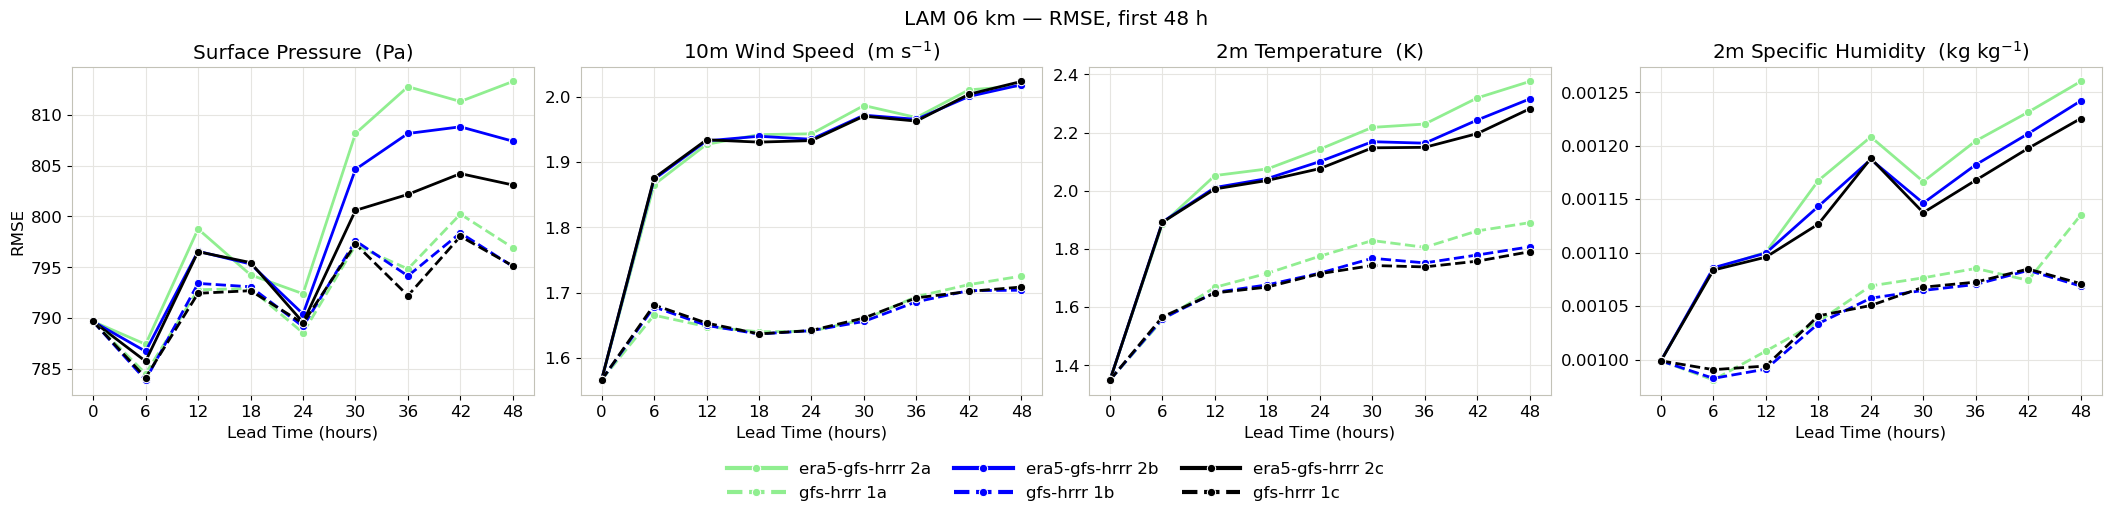

In [7]:
fig, axs = plot_surface_vars(rmse, metric_name="RMSE", surface_vars=LAM_SURFACE_VARS,
                             sel=dict(SHORT_LEAD), marker="o")
fig.suptitle("LAM 06 km — RMSE, first 48 h", y=1.06)


Text(0.5, 1.06, 'LAM 06 km — RMSE, full 360 h')

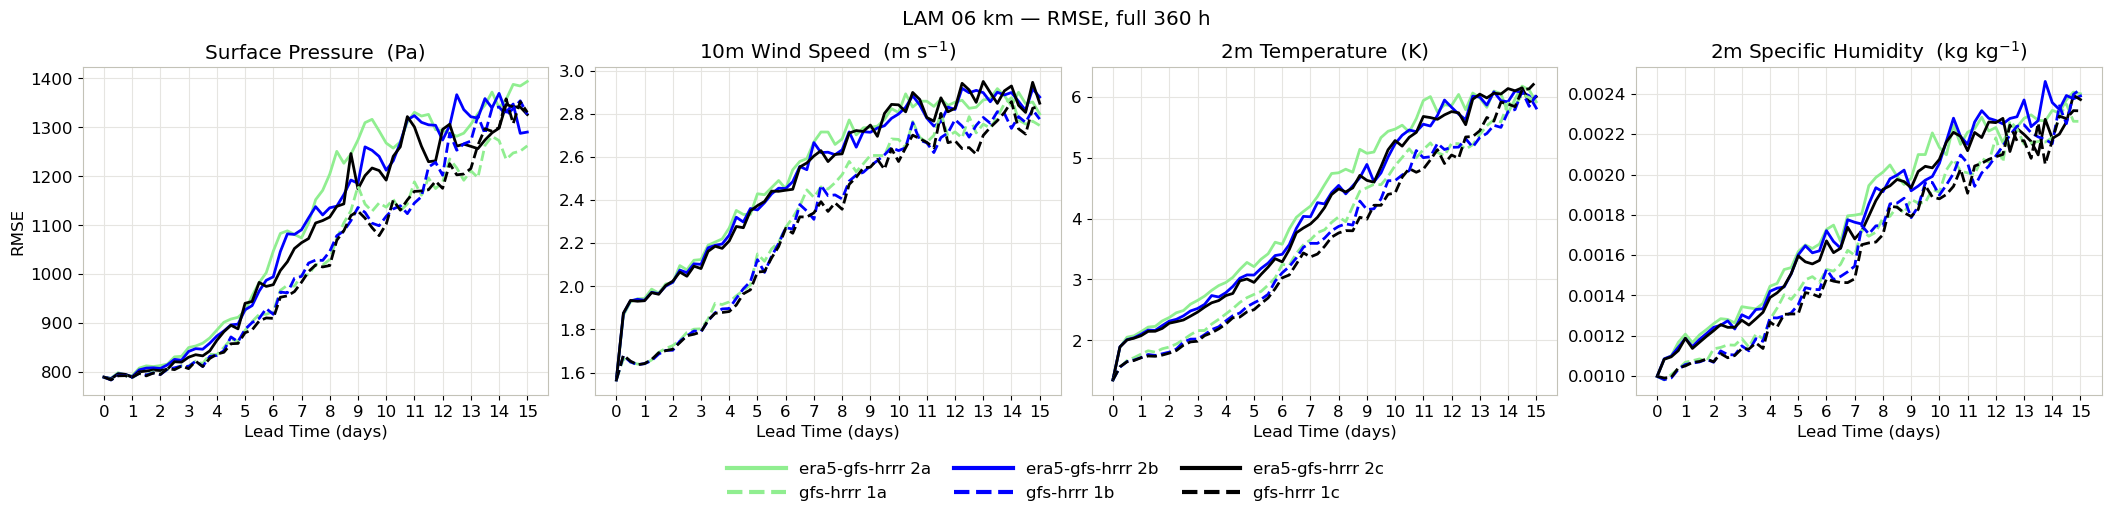

In [8]:
fig, axs = plot_surface_vars(rmse, metric_name="RMSE", surface_vars=LAM_SURFACE_VARS)
fig.suptitle("LAM 06 km — RMSE, full 360 h", y=1.06)

Text(0.5, 1.06, 'LAM 06 km — MAE, full 360 h')

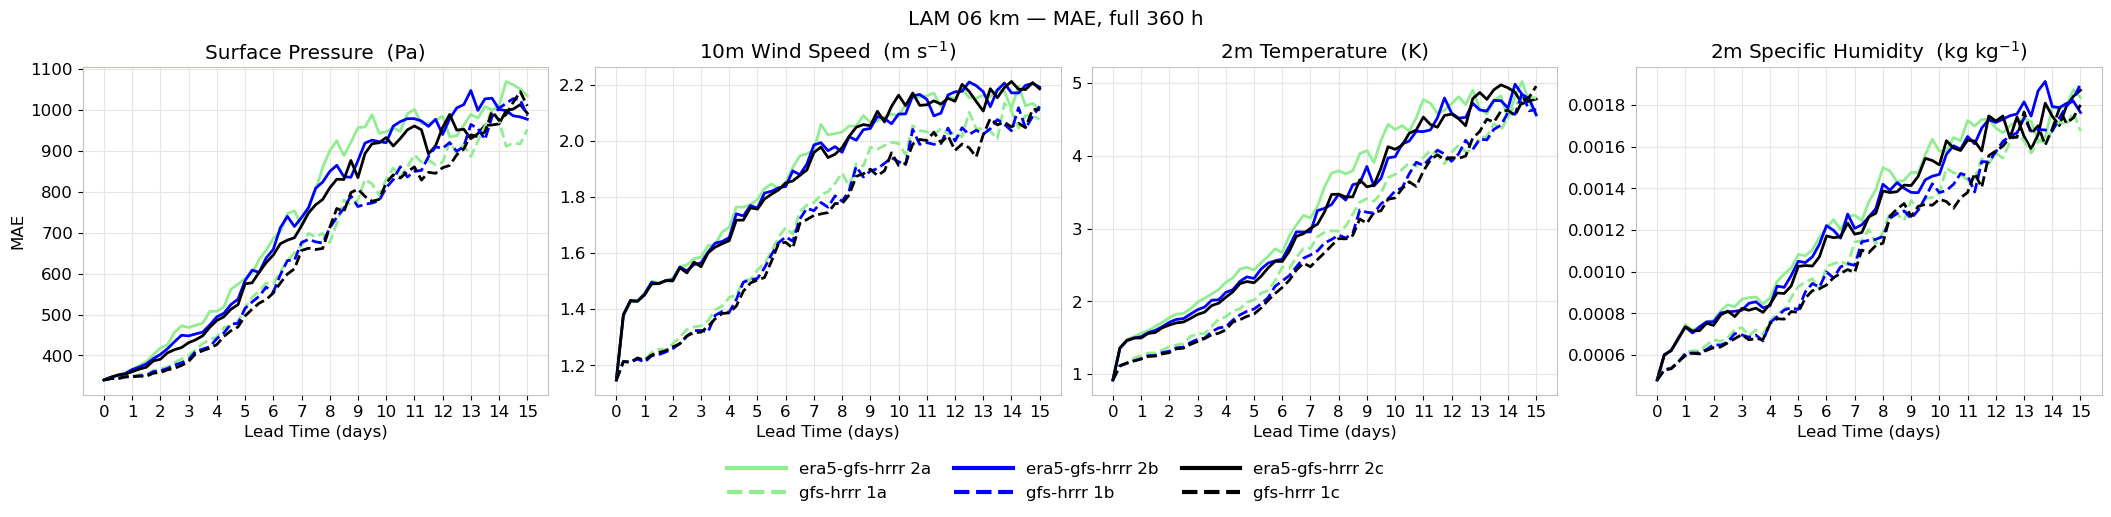

In [9]:
fig, axs = plot_surface_vars(mae, metric_name="MAE", surface_vars=LAM_SURFACE_VARS)
fig.suptitle("LAM 06 km — MAE, full 360 h", y=1.06)

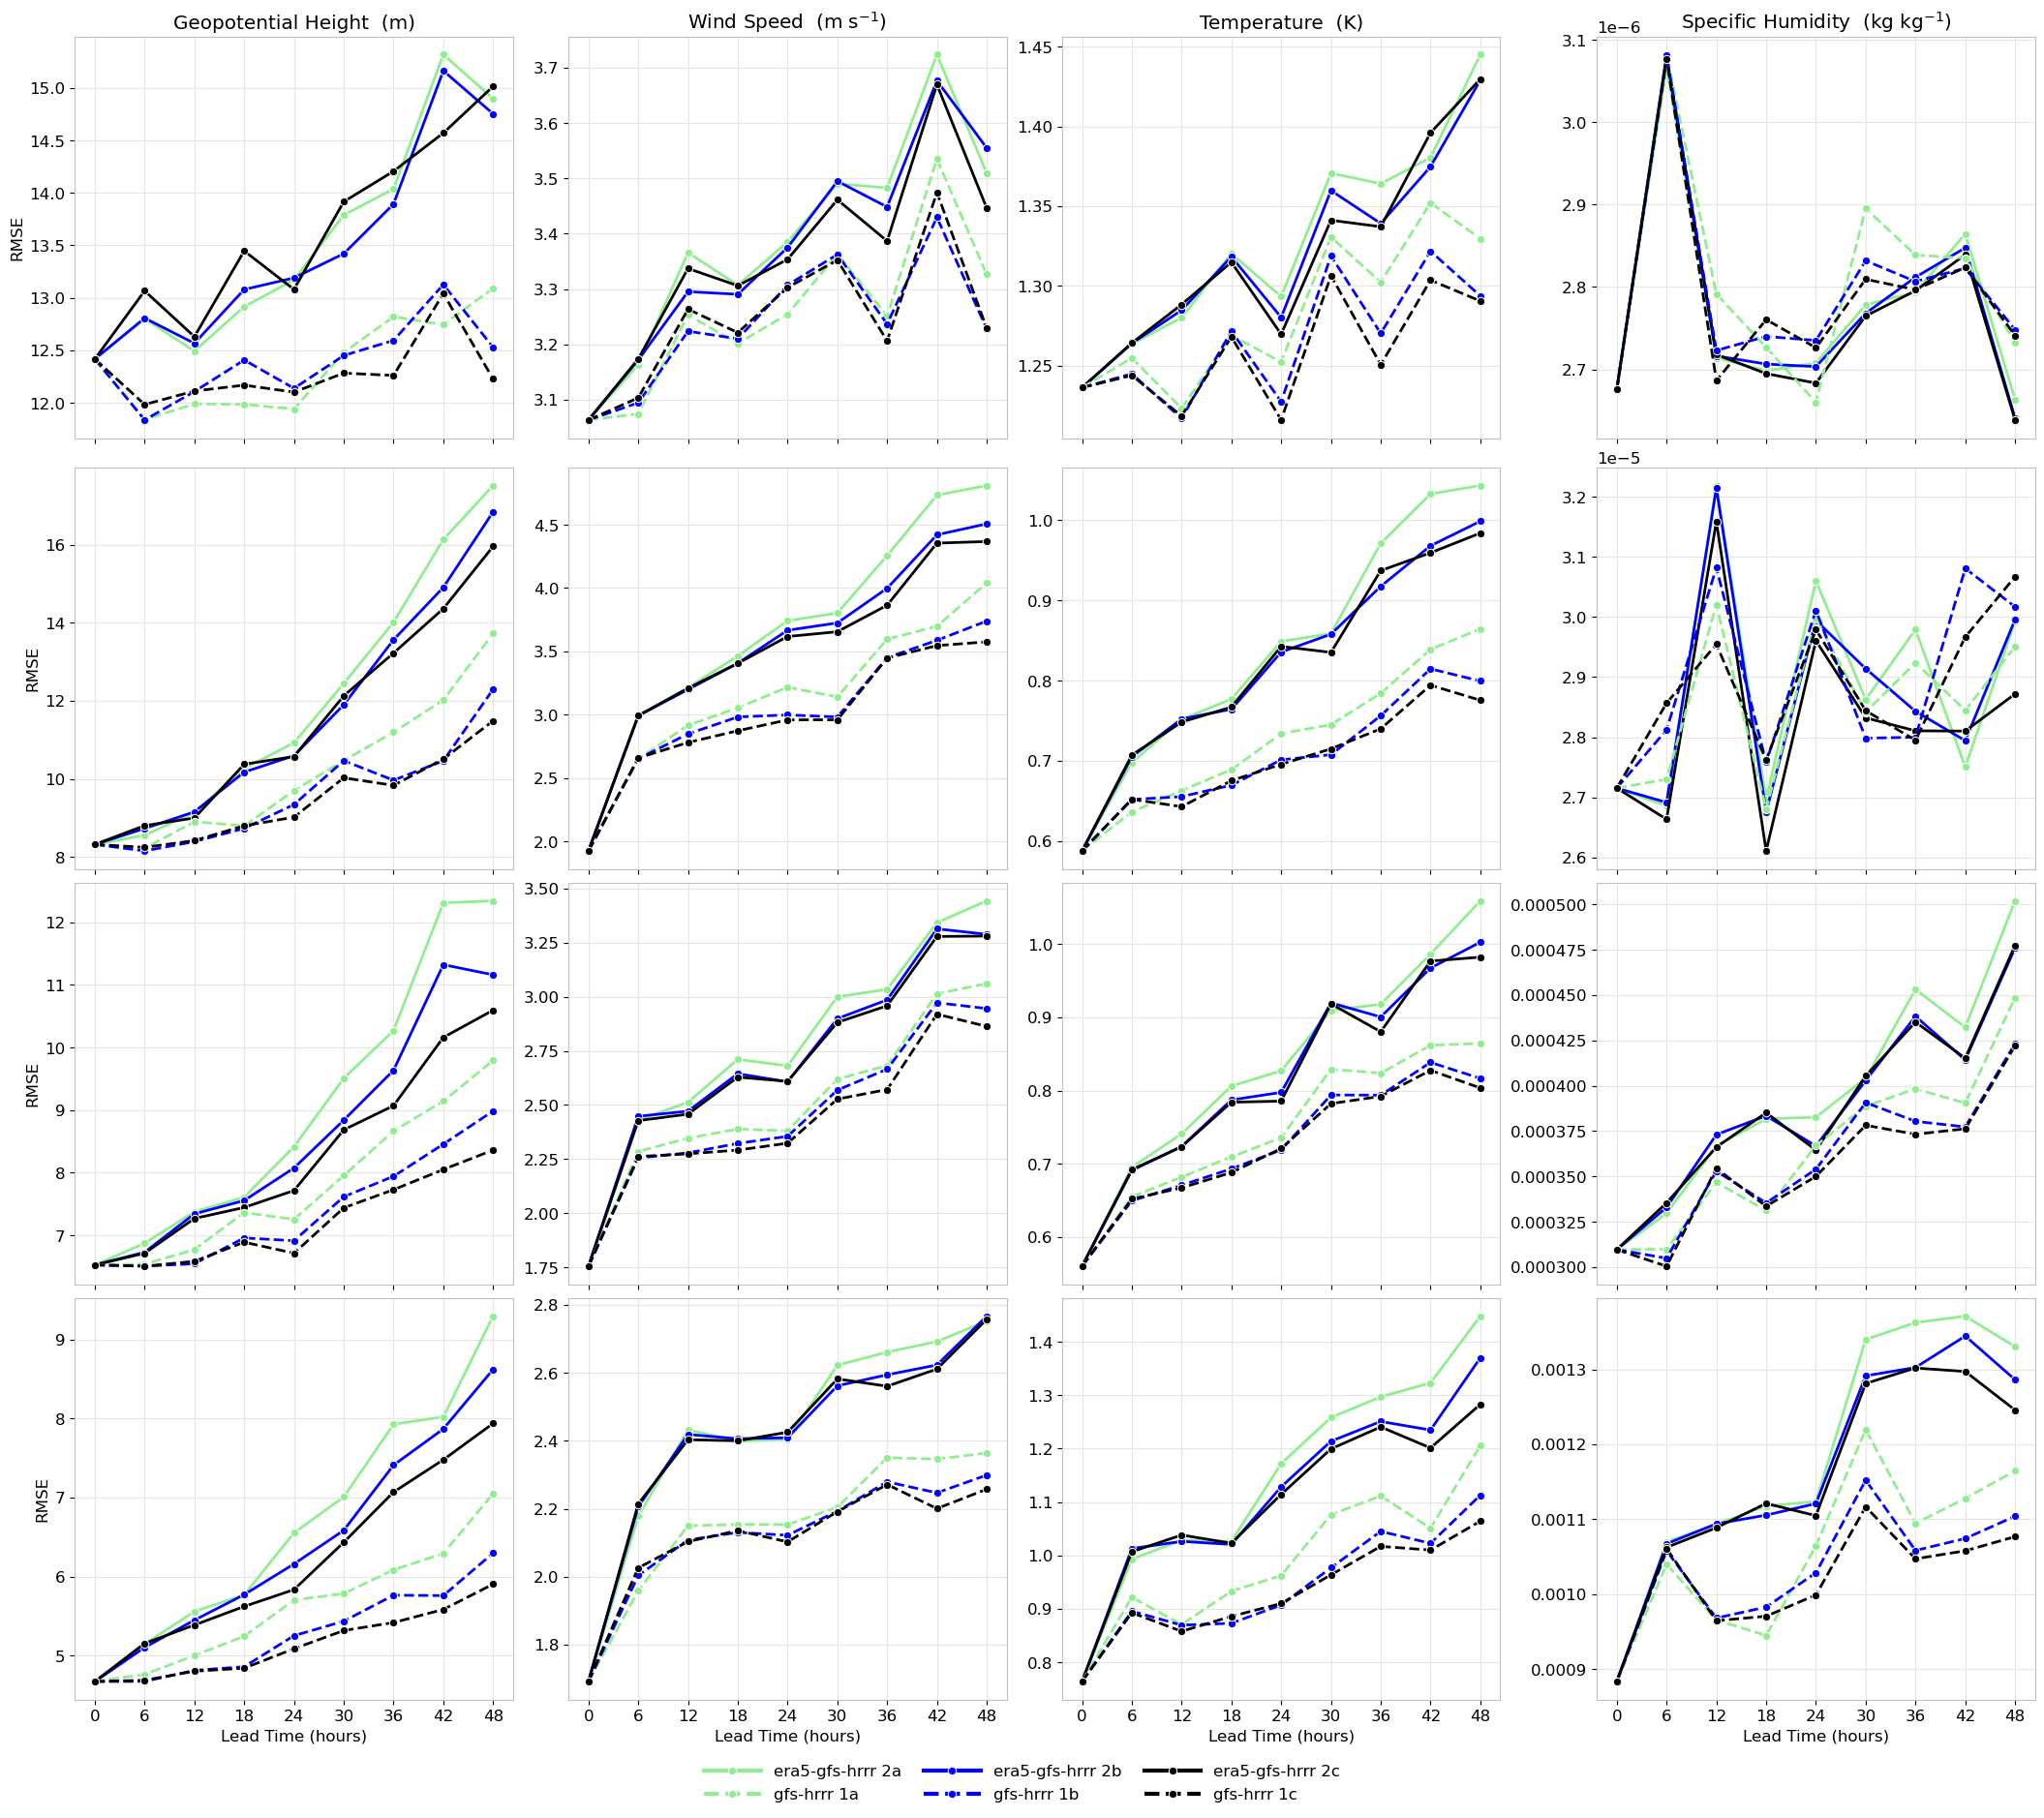

In [10]:
fig, axs = plot_level_vars(rmse, metric_name="RMSE", level_vars=LAM_LEVEL_VARS,
                           sel=dict(SHORT_LEAD), marker="o")

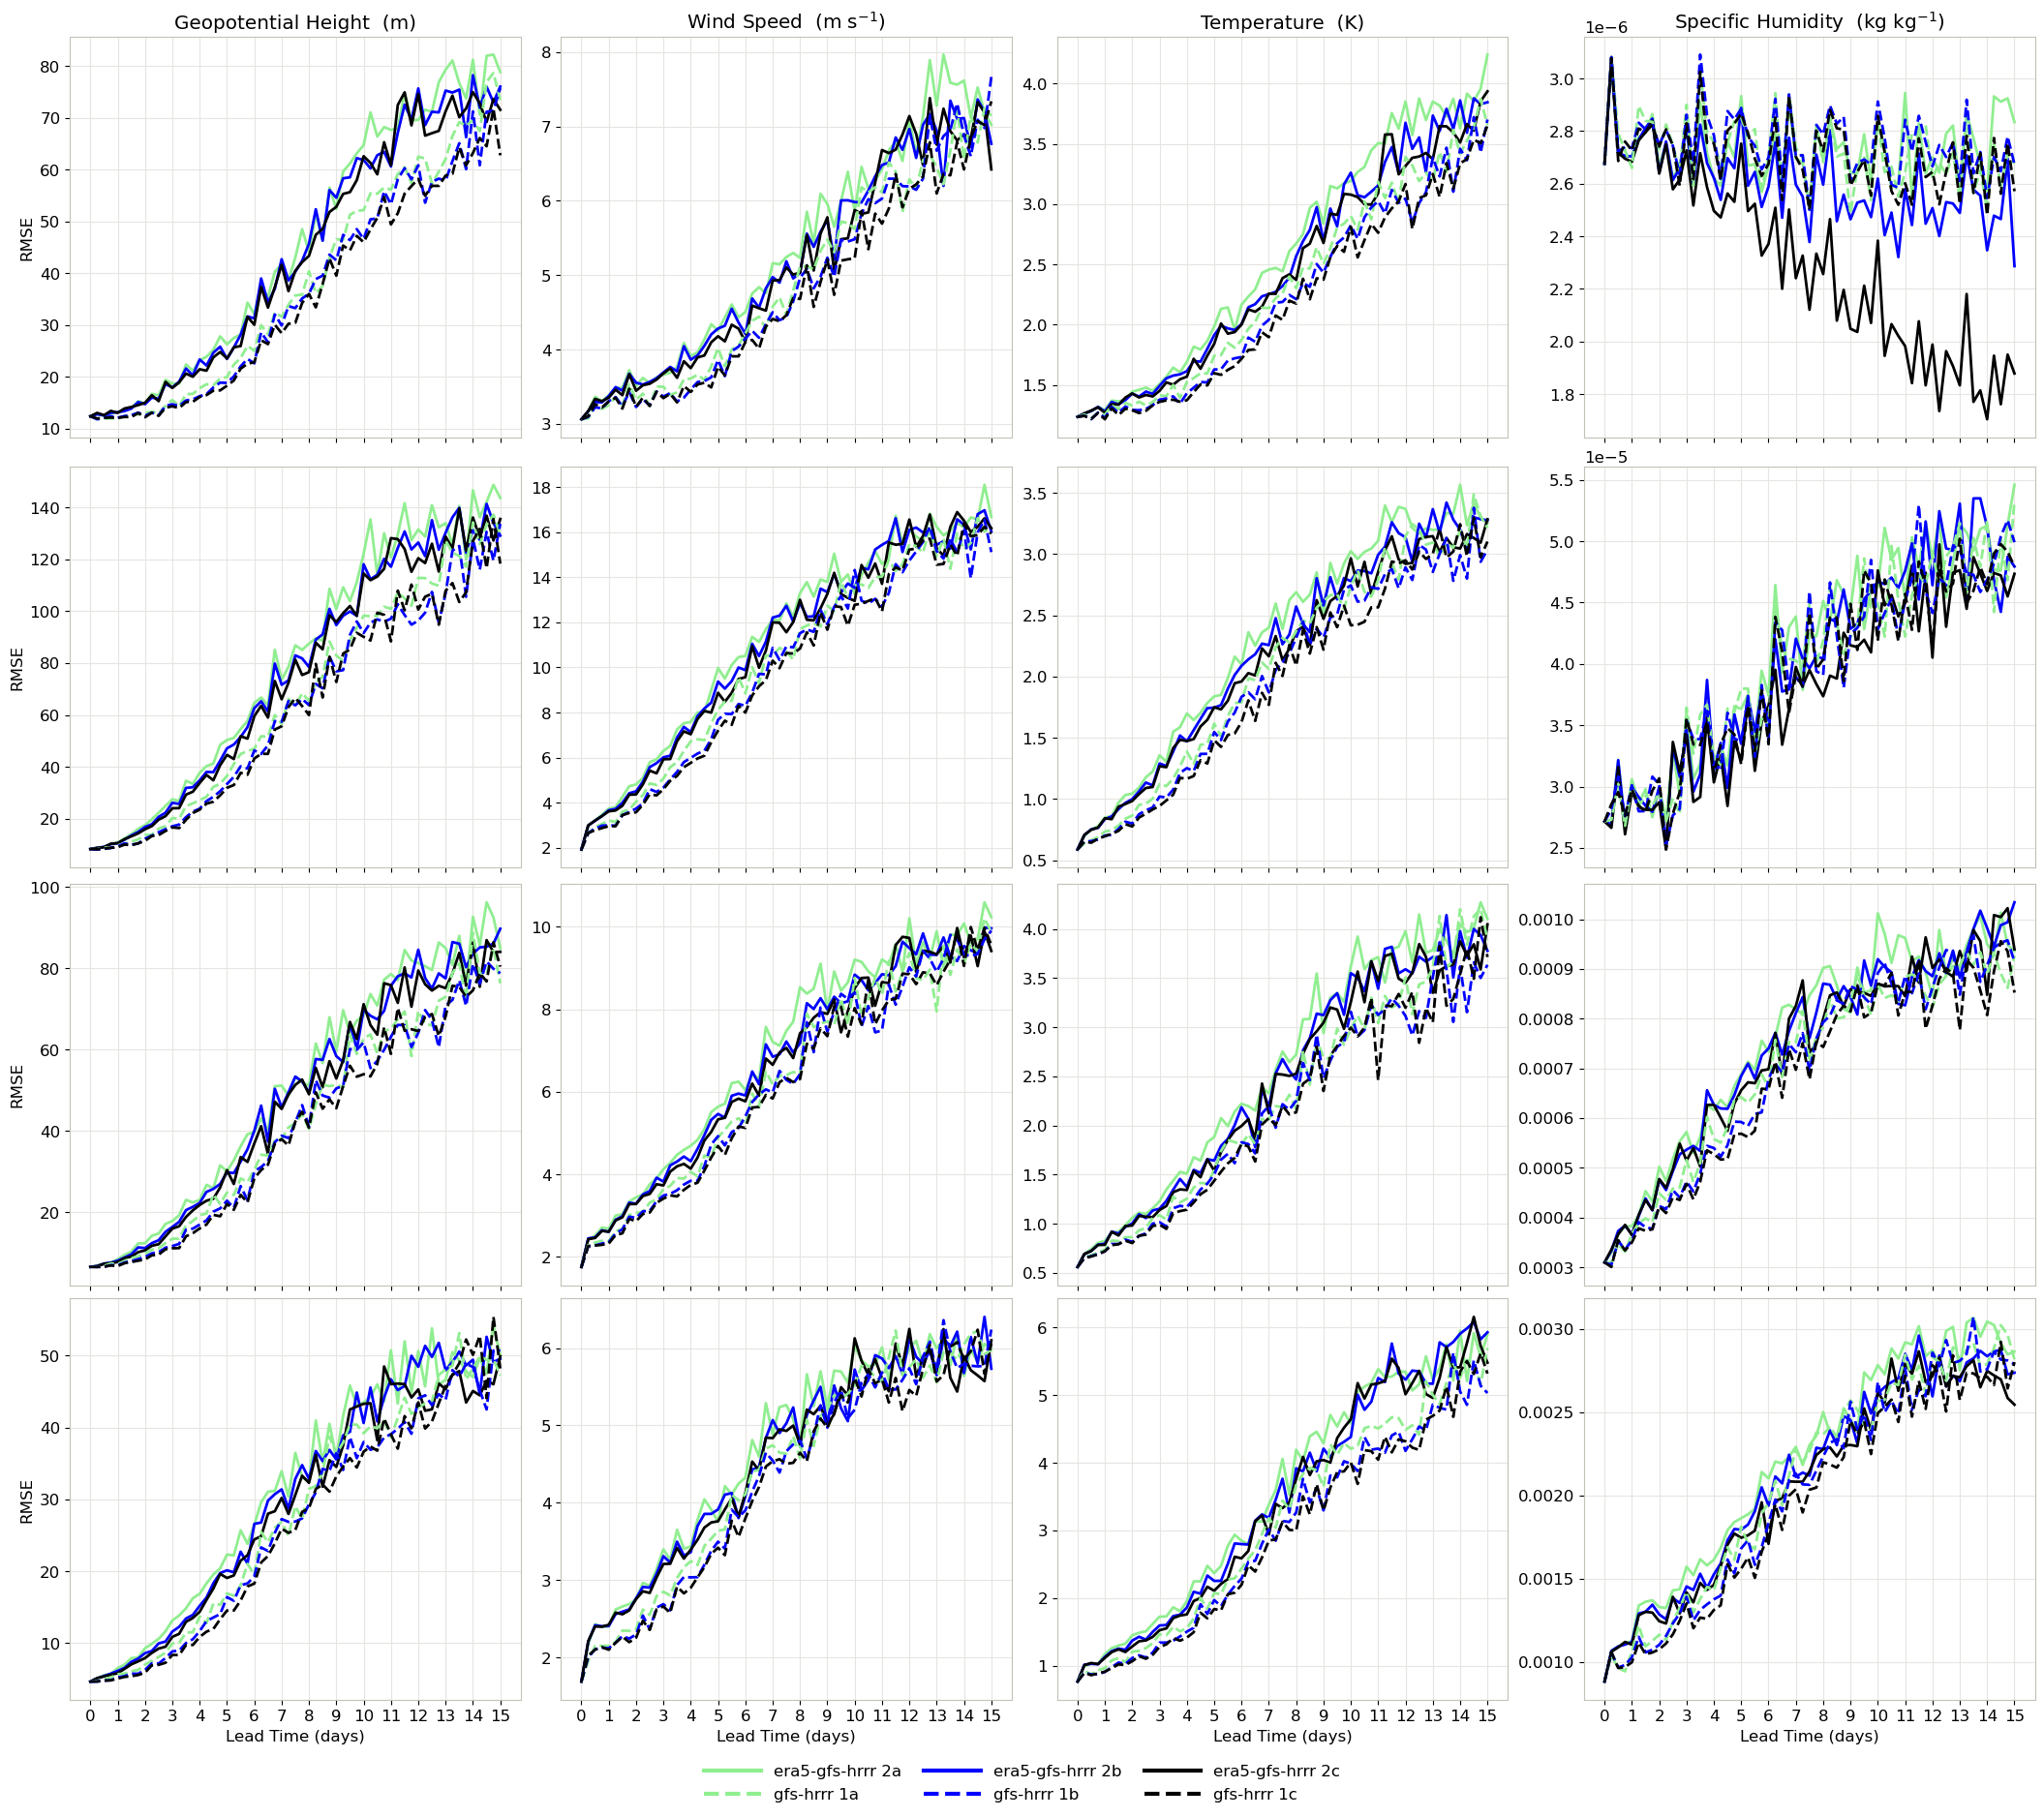

In [11]:
fig, axs = plot_level_vars(rmse, metric_name="RMSE", level_vars=LAM_LEVEL_VARS)

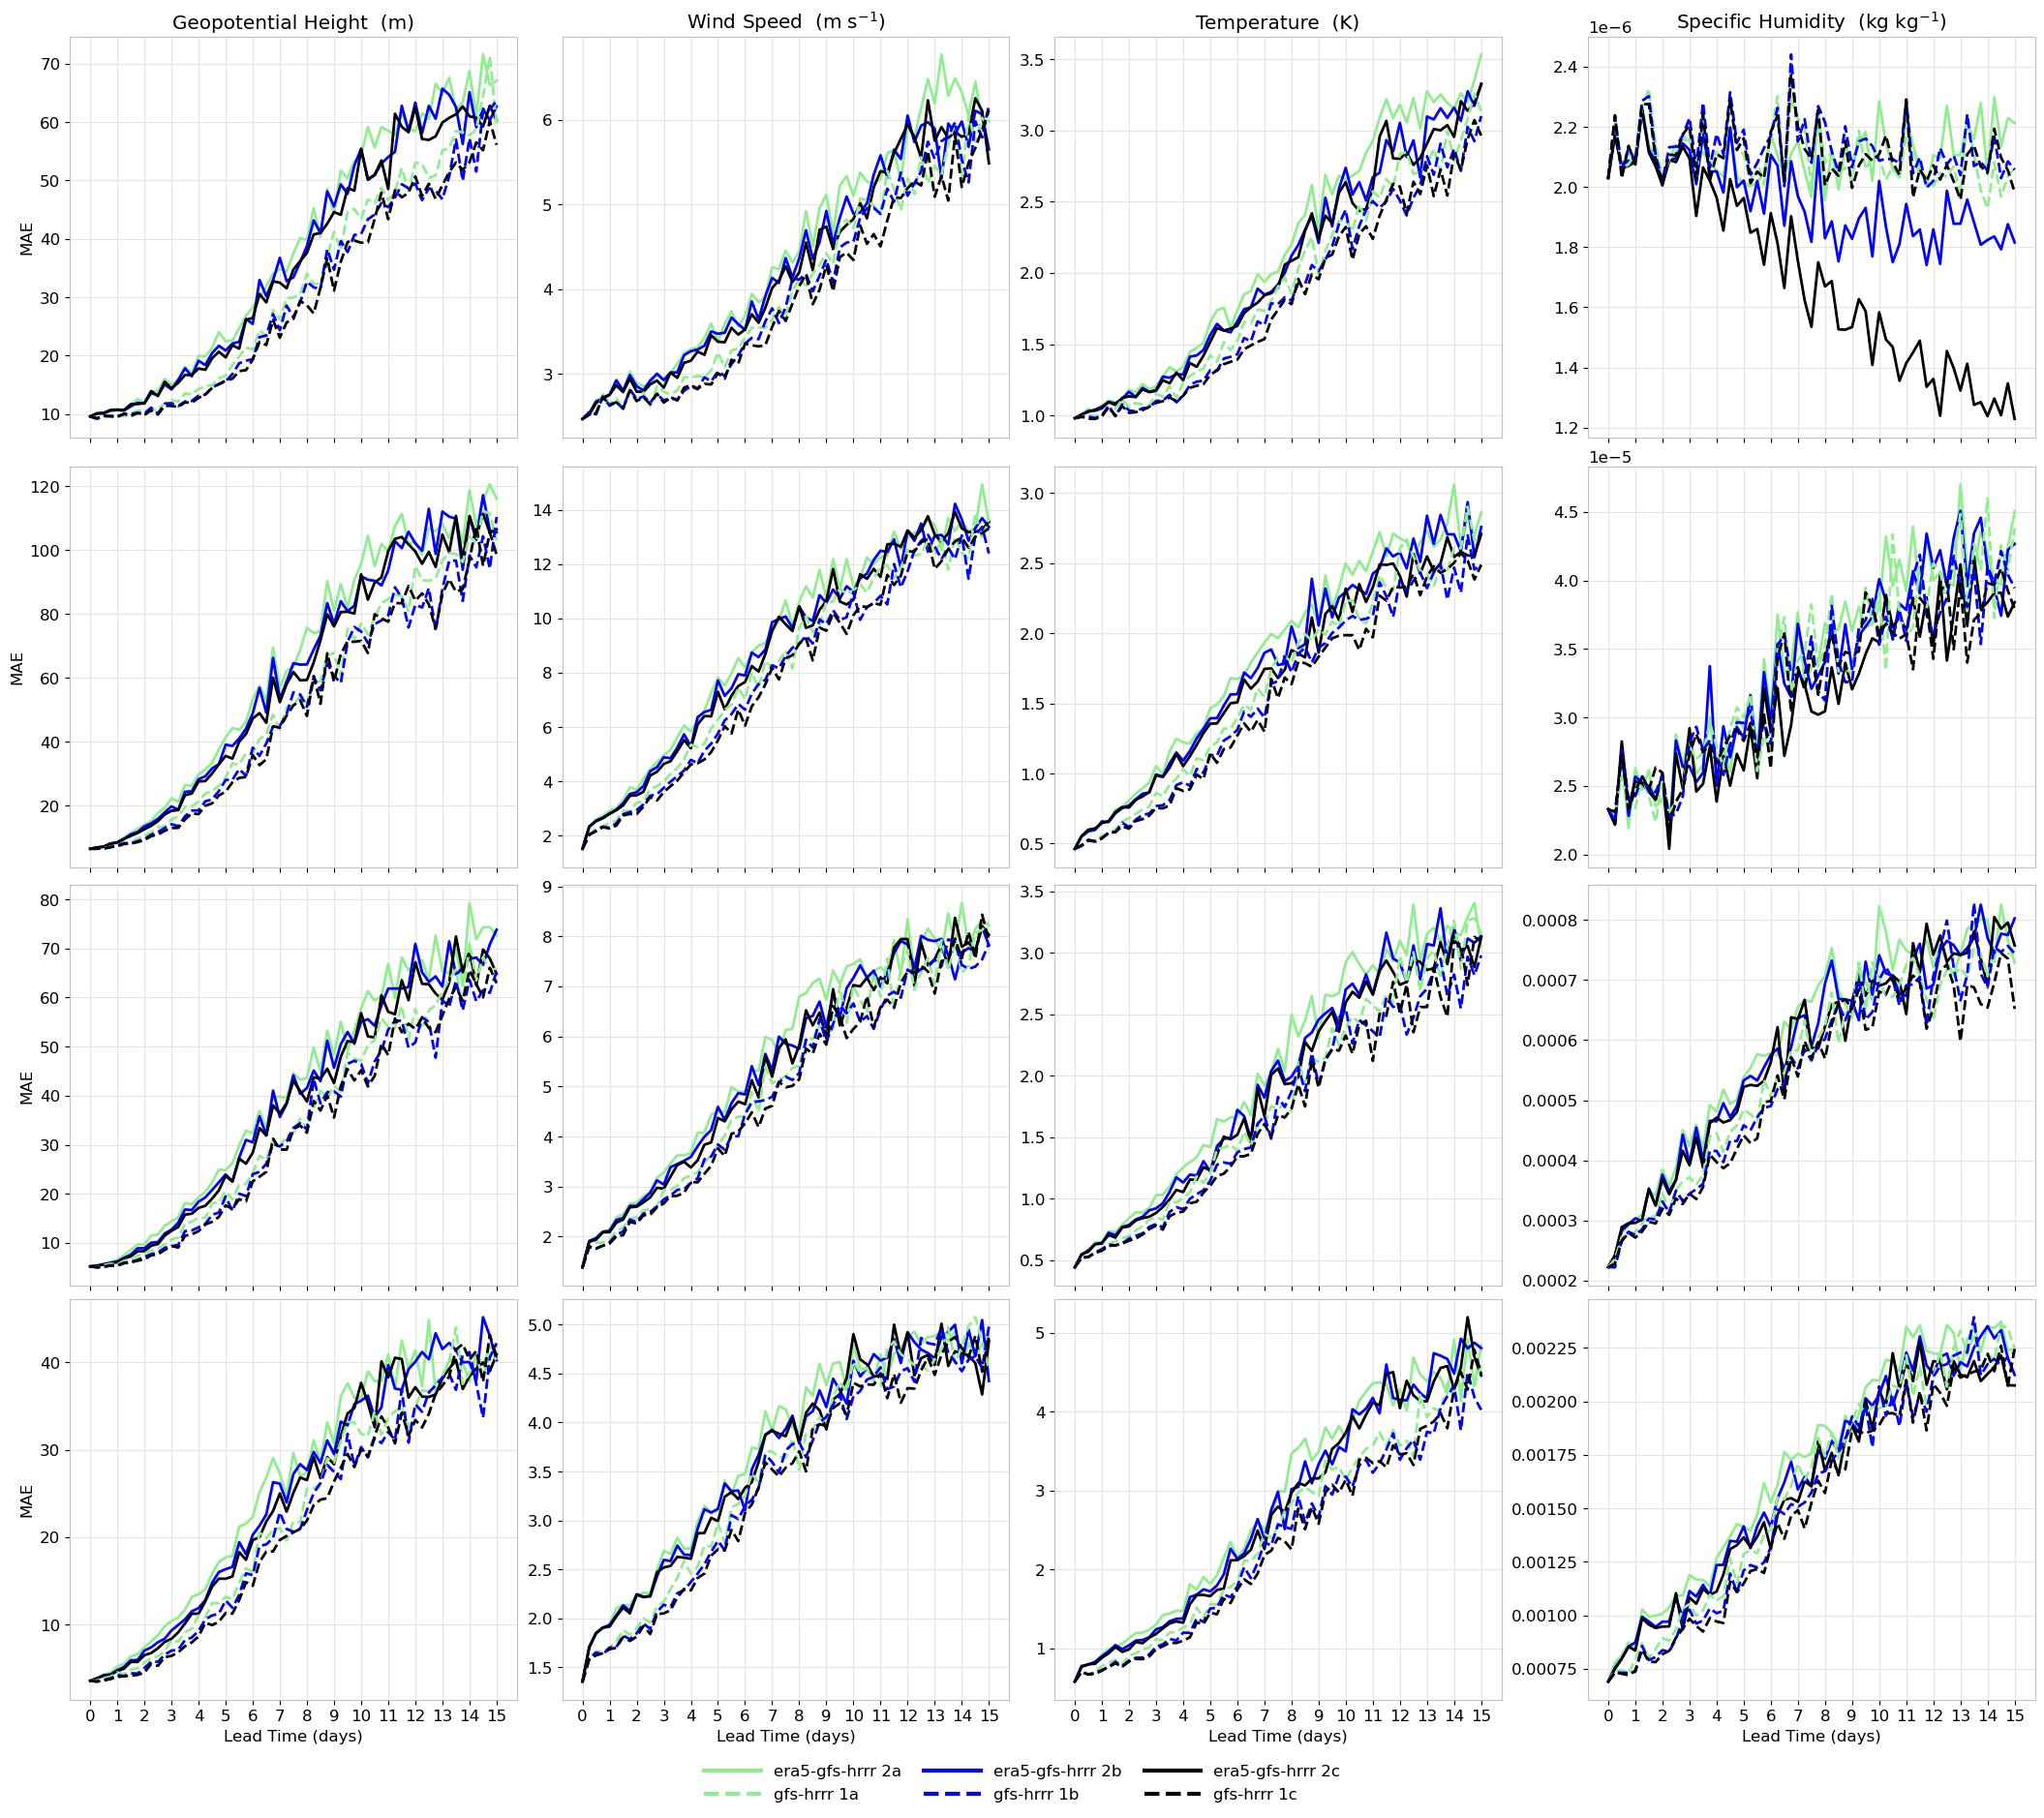

In [12]:
fig, axs = plot_level_vars(mae, metric_name="MAE", level_vars=LAM_LEVEL_VARS)

## 2. CONUS subregion — all eleven runs

The coarse (global / nested-global) verification restricted to CONUS. This is **not** a
06 km LAM score — it is the only comparison over the nest region that the global-grid runs
(`era5-gfs-hrrr 1a/1b` and the three `gfs-only` runs) can take part in. As in the global
notebook, only the variables common to all eleven are plotted: `era5-gfs-hrrr 1a/1b` carry
no `geopotential_height` and no `2m_specific_humidity`.


In [13]:
rmse_conus = load_conus("rmse")
mae_conus = load_conus("mae")

CONUS_SURFACE_VARS = common_vars(rmse_conus, SURFACE_CANDIDATES)
CONUS_LEVEL_VARS = common_vars(rmse_conus, LEVEL_CANDIDATES)

for label, ds in rmse_conus.items():
    missing = sorted(set(SURFACE_CANDIDATES + LEVEL_CANDIDATES) - set(ds.data_vars))
    print(f"{label:>18}: {ds.sizes['t0']} inits" + (f", missing {missing}" if missing else ""))

print(f"\nsurface vars: {CONUS_SURFACE_VARS}")
print(f"level vars:   {CONUS_LEVEL_VARS}")


  era5-gfs-hrrr 1a: 113 inits, missing ['2m_specific_humidity', 'geopotential_height']
  era5-gfs-hrrr 1b: 113 inits, missing ['2m_specific_humidity', 'geopotential_height']
  era5-gfs-hrrr 2a: 113 inits
  era5-gfs-hrrr 2b: 113 inits
  era5-gfs-hrrr 2c: 113 inits
       gfs-hrrr 1a: 113 inits
       gfs-hrrr 1b: 113 inits
       gfs-hrrr 1c: 113 inits
       gfs-only 1a: 113 inits
       gfs-only 1b: 113 inits
       gfs-only 1c: 113 inits

surface vars: ('surface_pressure', '10m_wind_speed', '2m_temperature')
level vars:   ('wind_speed', 'temperature', 'specific_humidity')


Text(0.5, 1.06, 'CONUS (coarse verification) — RMSE, first 48 h')

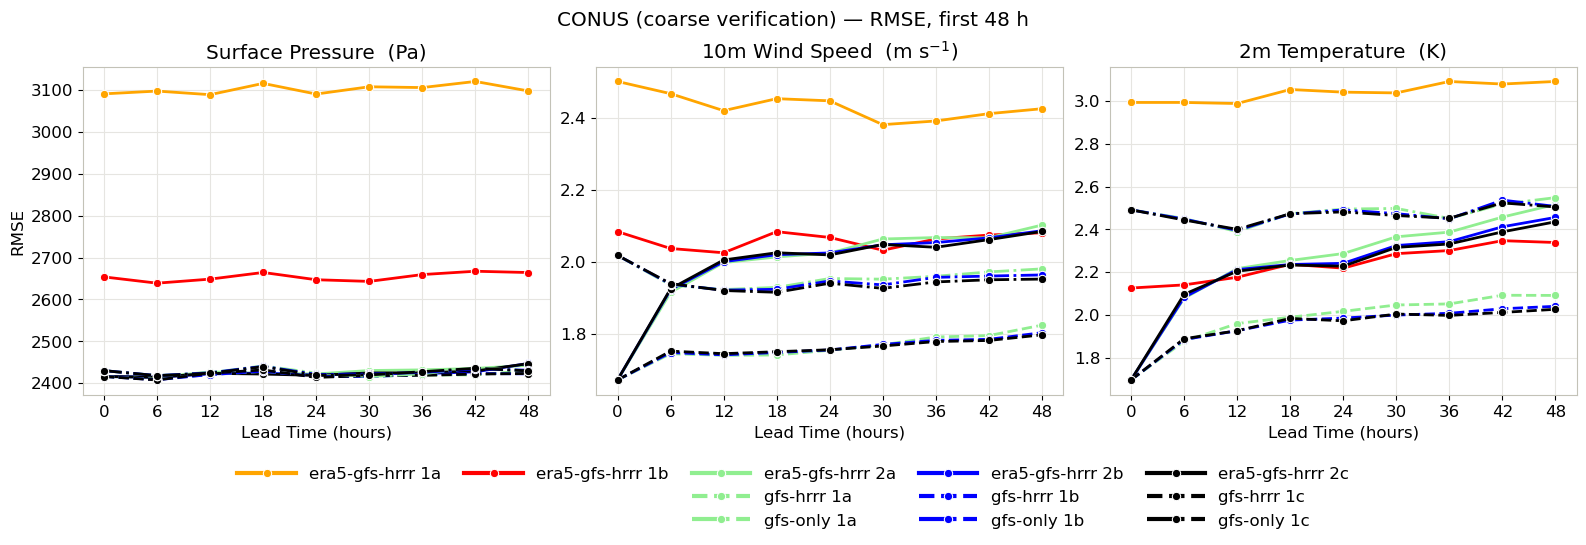

In [14]:
fig, axs = plot_surface_vars(rmse_conus, metric_name="RMSE", surface_vars=CONUS_SURFACE_VARS,
                             sel=dict(SHORT_LEAD), marker="o")
fig.suptitle("CONUS (coarse verification) — RMSE, first 48 h", y=1.06)

Text(0.5, 1.06, 'CONUS (coarse verification) — RMSE, full 360 h')

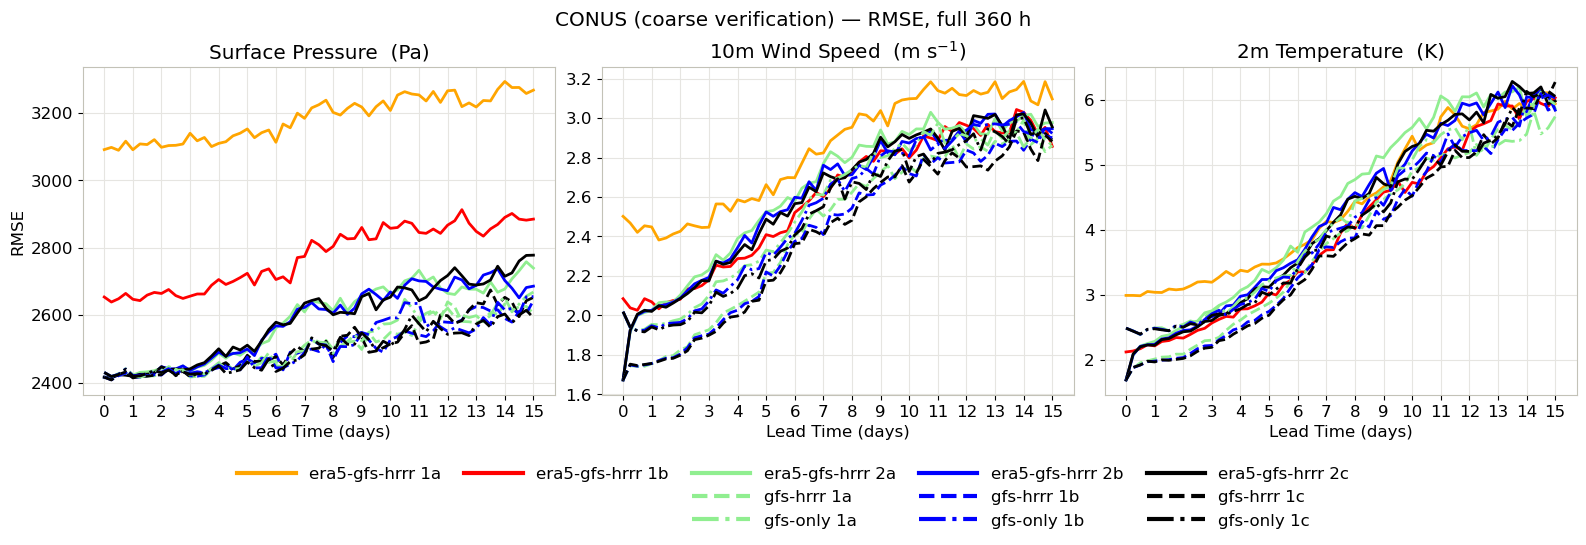

In [15]:
fig, axs = plot_surface_vars(rmse_conus, metric_name="RMSE", surface_vars=CONUS_SURFACE_VARS)
fig.suptitle("CONUS (coarse verification) — RMSE, full 360 h", y=1.06)

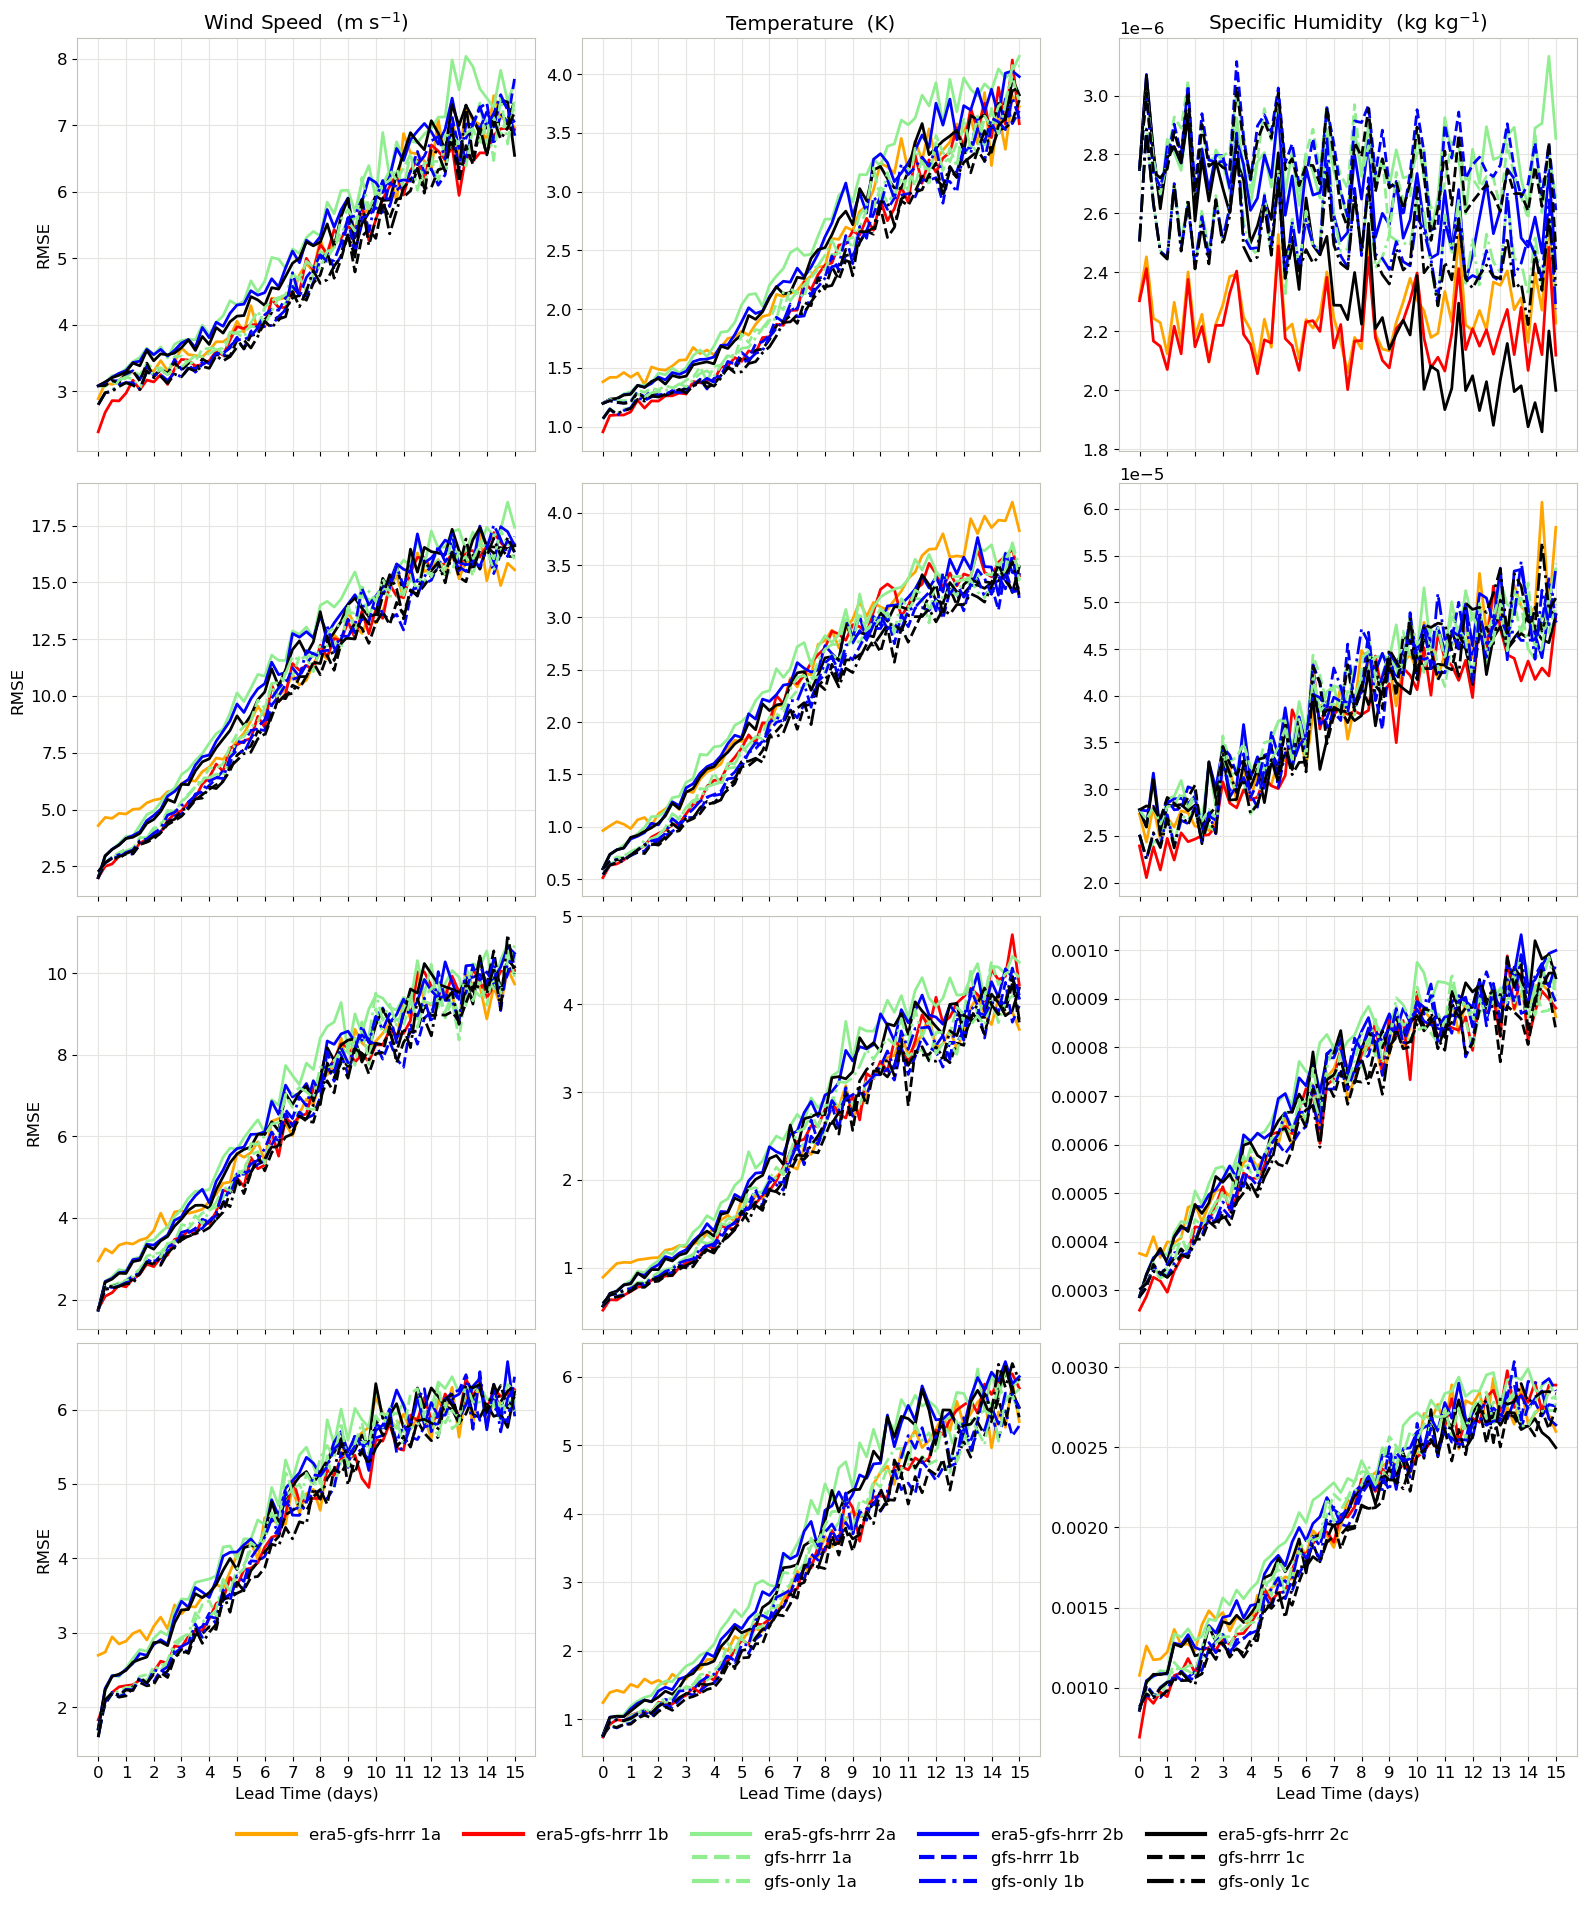

In [16]:
fig, axs = plot_level_vars(rmse_conus, metric_name="RMSE", level_vars=CONUS_LEVEL_VARS)

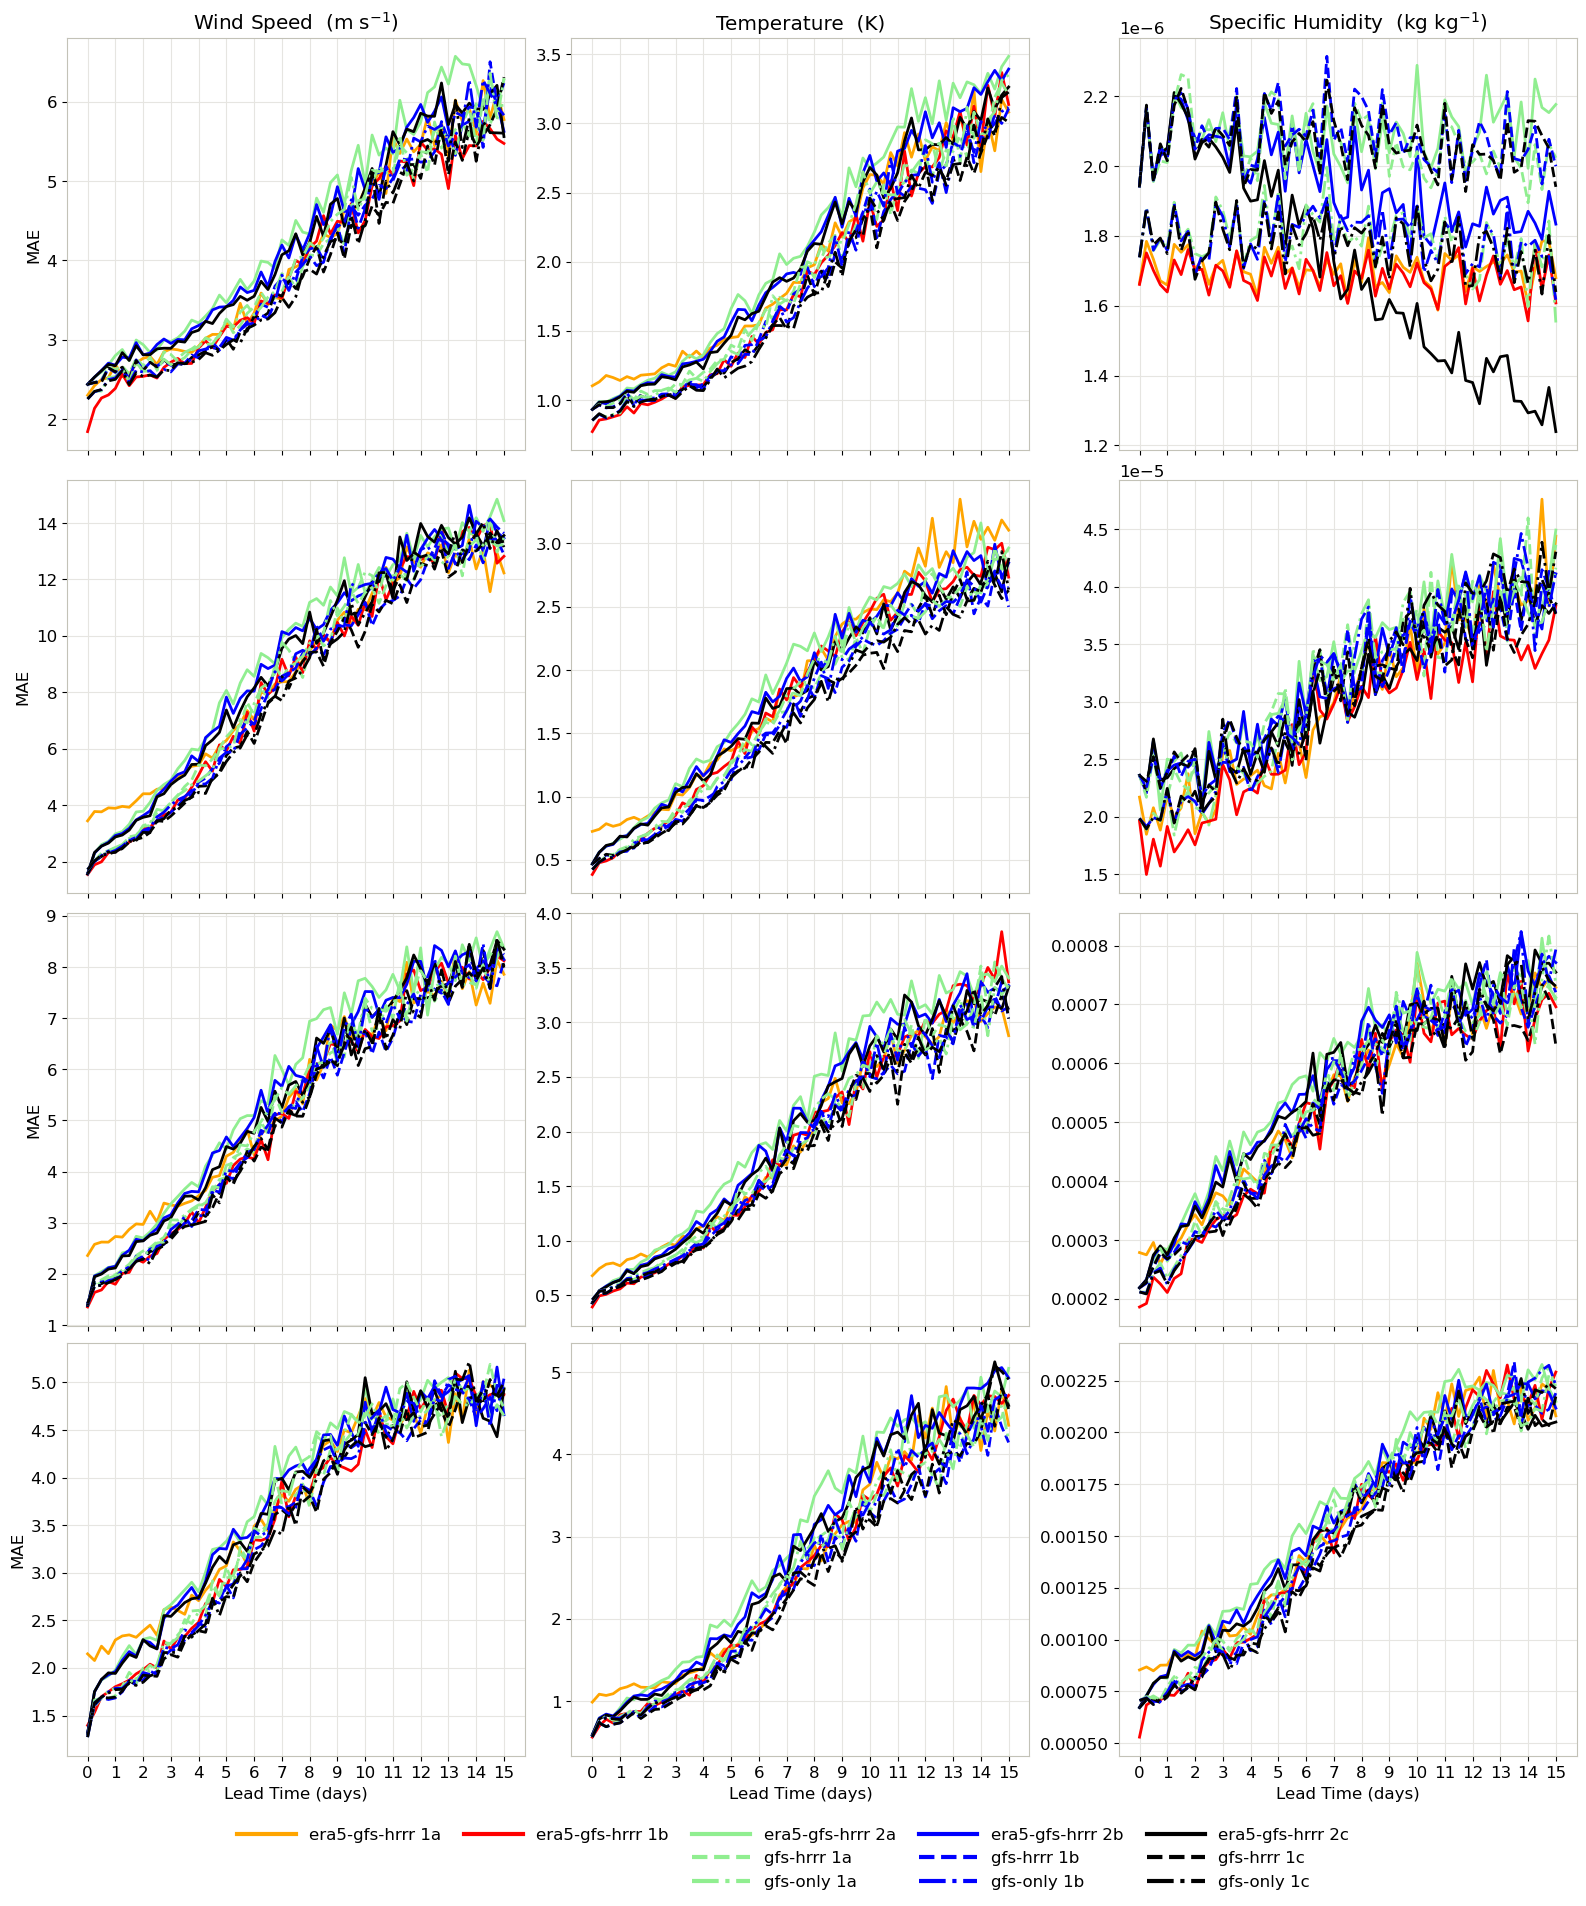

In [17]:
fig, axs = plot_level_vars(mae_conus, metric_name="MAE", level_vars=CONUS_LEVEL_VARS)

## Table view

The numbers behind the curves at a few lead times — also what makes the lower-contrast
series readable without relying on color.

In [18]:
import pandas as pd

def summary_table(dsdict, varname, fhrs=(0, 6, 12, 24, 48, 120, 360), level=None, stat="median"):
    rows = {}
    for label, ds in dsdict.items():
        if varname not in ds.data_vars:
            continue
        da = ds[varname]
        if level is not None:
            da = da.sel(level=level)
        reduced = da.median("t0") if stat == "median" else da.mean("t0")
        rows[label] = reduced.sel(fhr=list(fhrs)).to_series()
    df = pd.DataFrame(rows)
    df.index.name = "fhr"
    return df

print("LAM 06 km — RMSE 2m_temperature (K), median over inits")
display(summary_table(rmse, "2m_temperature").round(3))

print("\nLAM 06 km — RMSE 10m_wind_speed (m/s), median over inits")
display(summary_table(rmse, "10m_wind_speed").round(3))

print("\nCONUS (coarse) — RMSE 2m_temperature (K), median over inits")
display(summary_table(rmse_conus, "2m_temperature").round(3))

LAM 06 km — RMSE 2m_temperature (K), median over inits


,era5-gfs-hrrr 2a,era5-gfs-hrrr 2b,era5-gfs-hrrr 2c,gfs-hrrr 1a,gfs-hrrr 1b,gfs-hrrr 1c
fhr,,,,,,
0,1.350,1.350,1.350,1.350,1.350,1.350
6,1.886,1.893,1.892,1.556,1.561,1.567
12,2.053,2.011,2.006,1.668,1.651,1.649
24,2.143,2.101,2.076,1.775,1.717,1.715
48,2.376,2.316,2.282,1.891,1.807,1.791
120,3.211,3.072,2.952,2.754,2.616,2.503
360,5.917,5.815,6.002,5.898,6.025,6.252



LAM 06 km — RMSE 10m_wind_speed (m/s), median over inits


,era5-gfs-hrrr 2a,era5-gfs-hrrr 2b,era5-gfs-hrrr 2c,gfs-hrrr 1a,gfs-hrrr 1b,gfs-hrrr 1c
fhr,,,,,,
0,1.566,1.566,1.566,1.566,1.566,1.566
6,1.866,1.874,1.876,1.665,1.678,1.681
12,1.927,1.933,1.934,1.648,1.650,1.653
24,1.944,1.935,1.933,1.641,1.642,1.642
48,2.017,2.019,2.024,1.725,1.704,1.709
120,2.429,2.354,2.374,2.150,2.124,2.066
360,2.799,2.877,2.849,2.745,2.775,2.835



CONUS (coarse) — RMSE 2m_temperature (K), median over inits


,era5-gfs-hrrr 1a,era5-gfs-hrrr 1b,era5-gfs-hrrr 2a,era5-gfs-hrrr 2b,era5-gfs-hrrr 2c,gfs-hrrr 1a,gfs-hrrr 1b,gfs-hrrr 1c,gfs-only 1a,gfs-only 1b,gfs-only 1c
fhr,,,,,,,,,,,
0,2.994,2.126,1.696,1.696,1.696,1.696,1.696,1.696,2.492,2.492,2.492
6,2.994,2.141,2.078,2.082,2.096,1.877,1.885,1.889,2.451,2.448,2.444
12,2.989,2.176,2.217,2.212,2.205,1.960,1.926,1.926,2.390,2.395,2.401
24,3.042,2.219,2.287,2.241,2.228,2.017,1.985,1.973,2.495,2.491,2.482
48,3.092,2.339,2.517,2.456,2.436,2.091,2.040,2.026,2.549,2.508,2.505
120,3.473,3.032,3.343,3.239,3.120,2.874,2.748,2.691,3.219,3.056,2.999
360,5.938,6.030,5.863,5.839,5.979,5.928,5.898,6.271,5.741,6.028,6.050


## Save every figure

Writes to `figures/` next to this notebook, with a `lam` or `conus` prefix so the files do
not collide with the ones the global-obs notebook writes.

In [19]:
def save_all(metrics=("rmse", "mae"), figdir=FIGDIR):
    # --- LAM nest, stage2 only
    for metric in metrics:
        name = metric.upper()
        data = load_lam(metric)
        svars = common_vars(data, SURFACE_CANDIDATES)
        lvars = common_vars(data, LEVEL_CANDIDATES)

        fig, _ = plot_surface_vars(data, metric_name=name, surface_vars=svars,
                                   sel=dict(SHORT_LEAD), marker="o")
        fig.savefig(f"{figdir}/lam_surface_48h_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        fig, _ = plot_surface_vars(data, metric_name=name, surface_vars=svars)
        fig.savefig(f"{figdir}/lam_surface_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        fig, _ = plot_level_vars(data, metric_name=name, level_vars=lvars,
                                 sel=dict(SHORT_LEAD), marker="o")
        fig.savefig(f"{figdir}/lam_plevel_48h_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        fig, _ = plot_level_vars(data, metric_name=name, level_vars=lvars)
        fig.savefig(f"{figdir}/lam_plevel_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        for ds in data.values():
            ds.close()
        print(f"wrote lam {metric}")

    # --- CONUS subregion, all five stages
    for metric in metrics:
        name = metric.upper()
        data = load_conus(metric)
        svars = common_vars(data, SURFACE_CANDIDATES)
        lvars = common_vars(data, LEVEL_CANDIDATES)

        fig, _ = plot_surface_vars(data, metric_name=name, surface_vars=svars,
                                   sel=dict(SHORT_LEAD), marker="o")
        fig.savefig(f"{figdir}/conus_surface_48h_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        fig, _ = plot_surface_vars(data, metric_name=name, surface_vars=svars)
        fig.savefig(f"{figdir}/conus_surface_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        fig, _ = plot_level_vars(data, metric_name=name, level_vars=lvars)
        fig.savefig(f"{figdir}/conus_plevel_{metric}.jpeg", dpi=300, bbox_inches="tight")
        plt.close(fig)

        for ds in data.values():
            ds.close()
        print(f"wrote conus {metric}")


save_all()

wrote lam rmse


wrote lam mae


wrote conus rmse


wrote conus mae
